## Import librairies

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import random
import numpy as np
import pandas as pd
from pathlib import Path

from torch.utils.data import Dataset

## First librosa test

In [2]:
y, sr = librosa.load("sample.wav", sr=None)
print(y, "Sampling rate : ",sr)
print(1/sr * len(y), "seconds")

/Users/matiscodjia/Dev/tinys/Classifhear/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[ 0.08169556  0.08596802  0.08830261 ... -0.03619385 -0.03863525
 -0.04307556] Sampling rate :  44100
4.0 seconds


## Features extraction 

### Temporal features extraction

In [26]:
FRAMESIZE=2048
HOP_LENGTH=256
#Extract amplitude envelope function
def extract_amplitude_envelope(y, framesize=FRAMESIZE, hop_length=HOP_LENGTH):
    ae = []
    for i in range(0, len(y) - framesize + 1, hop_length):
        ae.append(max(abs(y[i:i+framesize])))
    return np.array(ae)




#### Test 

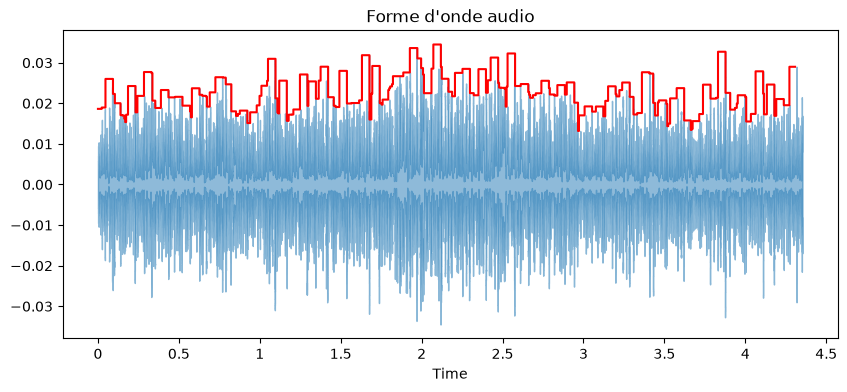

In [24]:

ae = extract_amplitude_envelope(y, hop_length=HOP_LENGTH)
t = librosa.frames_to_time(range(0, ae.size), hop_length=HOP_LENGTH, sr=sr)
fig, ax = plt.subplots(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr, ax=ax, alpha=0.5)
plt.plot(t, ae, color="r", drawstyle="steps-post")
plt.title('Forme d\'onde audio')
plt.show()


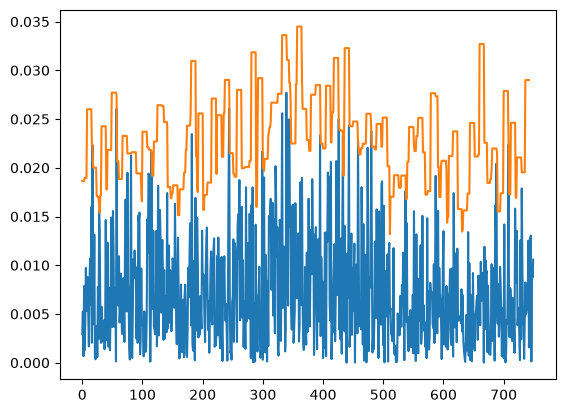

In [25]:
plt.plot(np.abs(y[::HOP_LENGTH]))
plt.plot(ae)

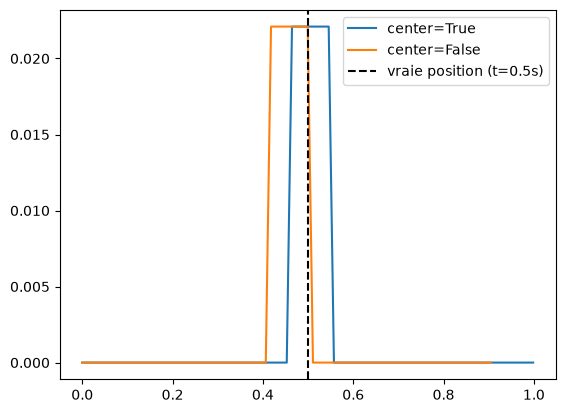

In [ ]:
sr = 22050
y_test = np.zeros(sr) 
y_test[sr//2] = 1.0   
rms_centered = librosa.feature.rms(y=y_test, frame_length=2048, hop_length=256, center=True)[0]
rms_nocenter = librosa.feature.rms(y=y_test, frame_length=2048, hop_length=256, center=False)[0]
t_c = librosa.frames_to_time(range(len(rms_centered)), sr=sr, hop_length=256)
t_n = librosa.frames_to_time(range(len(rms_nocenter)), sr=sr, hop_length=256)

plt.plot(t_c, rms_centered, label="center=True")
plt.plot(t_n, rms_nocenter, label="center=False")
plt.axvline(0.5, color="black", linestyle="--", label="vraie position (t=0.5s)")
plt.legend()
plt.show()

In [66]:
64*173

11072

In [51]:
2048 *4

8192

## Dataset loading

In [5]:
metadata = pd.read_csv("UrbanSound8K/metadata/UrbanSound8K.csv")

In [6]:
metadata

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.000000,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.500000,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.500000,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.000000,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.500000,72.500000,1,5,2,children_playing
...,...,...,...,...,...,...,...,...
8727,99812-1-2-0.wav,99812,159.522205,163.522205,2,7,1,car_horn
8728,99812-1-3-0.wav,99812,181.142431,183.284976,2,7,1,car_horn
8729,99812-1-4-0.wav,99812,242.691902,246.197885,2,7,1,car_horn
8730,99812-1-5-0.wav,99812,253.209850,255.741948,2,7,1,car_horn


In [7]:
def load_paths(df: pd.DataFrame, root_dir="UrbanSound8k/audio") -> pd.DataFrame:
    df['path'] = df.apply(lambda row: 
                          str(Path.cwd().resolve()/root_dir/f"fold{row['fold']}/{row['slice_file_name']}"), axis=1)
    return df

metadata = load_paths(metadata)
metadata

,slice_file_name,fsID,start,end,salience,fold,classID,class,path
0,100032-3-0-0.wav,100032,0.000000,0.317551,1,5,3,dog_bark,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
1,100263-2-0-117.wav,100263,58.500000,62.500000,1,5,2,children_playing,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
2,100263-2-0-121.wav,100263,60.500000,64.500000,1,5,2,children_playing,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
3,100263-2-0-126.wav,100263,63.000000,67.000000,1,5,2,children_playing,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
4,100263-2-0-137.wav,100263,68.500000,72.500000,1,5,2,children_playing,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
...,...,...,...,...,...,...,...,...,...
8727,99812-1-2-0.wav,99812,159.522205,163.522205,2,7,1,car_horn,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
8728,99812-1-3-0.wav,99812,181.142431,183.284976,2,7,1,car_horn,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
8729,99812-1-4-0.wav,99812,242.691902,246.197885,2,7,1,car_horn,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...
8730,99812-1-5-0.wav,99812,253.209850,255.741948,2,7,1,car_horn,/Users/matiscodjia/Dev/tinys/Classifhear/Urban...


In [8]:

class UrbanSound8kDataset(Dataset):
    def __init__(self, df):
        self.df = df
        
    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx]['path']
        label = self.df.iloc[idx]['class']
        signal, _ = librosa.load(path, sr=None)
        return (signal, label)


In [9]:
dataset = UrbanSound8kDataset(metadata)

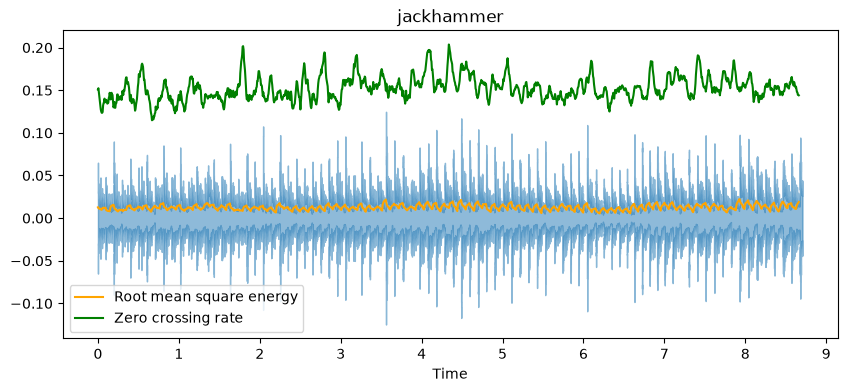

In [27]:
data = dataset[random.choice(range(len(dataset)))]
y, label = data
ae = extract_amplitude_envelope(y, hop_length=HOP_LENGTH)
rms = librosa.feature.rms(y=y, frame_length=FRAMESIZE, hop_length=HOP_LENGTH, center=False)[0]
zcr = librosa.feature.zero_crossing_rate(y=y, frame_length=FRAMESIZE, hop_length=HOP_LENGTH, center=False)[0]
t = librosa.frames_to_time(range(0, ae.size), hop_length=HOP_LENGTH, sr=sr)


len(ae)
fig, ax = plt.subplots(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr, ax=ax, alpha=0.5)
#plt.plot(t, ae, color="r", label="Amplitude envelope")
plt.plot(t, rms, color="orange",label="Root mean square energy")
plt.plot(t, zcr, color="green",label="Zero crossing rate")
plt.title(label)
plt.legend()
plt.show()